Akurasi Model (R2 Score) : 0.75
Tingkat Error (RMSE)     : 1.17



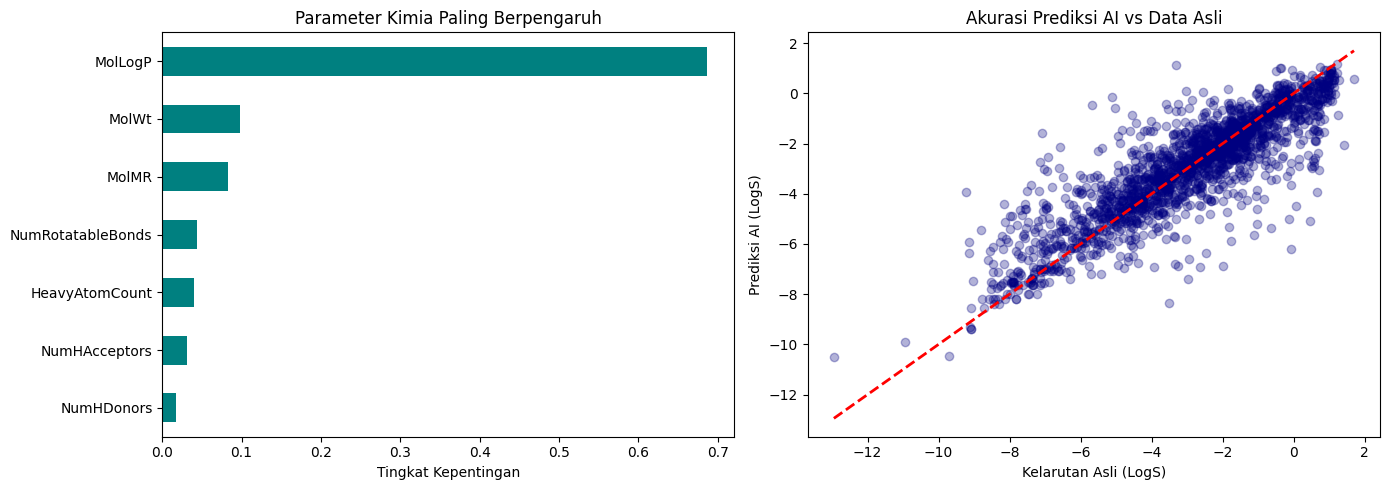

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 1. Membaca dataset
df = pd.read_csv('curated-solubility-dataset.csv')

# 2. Menentukan Fitur (Input) dan Target (Output)
fitur = ['MolWt', 'MolLogP', 'MolMR', 'HeavyAtomCount', 'NumHAcceptors', 'NumHDonors', 'NumRotatableBonds']
X = df[fitur]
y = df['Solubility']

# 3. Membagi data latih (80%) dan data uji (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Melatih Model AI (Random Forest)
model_ai = RandomForestRegressor(n_estimators=100, random_state=42)
model_ai.fit(X_train, y_train)

# 5. Membuat prediksi untuk data uji (ini yang tadi belum terbaca)
prediksi_test = model_ai.predict(X_test)

# 6. Menampilkan Skor Evaluasi
skor_r2 = r2_score(y_test, prediksi_test)
rmse = np.sqrt(mean_squared_error(y_test, prediksi_test))
print(f"Akurasi Model (R2 Score) : {skor_r2:.2f}")
print(f"Tingkat Error (RMSE)     : {rmse:.2f}\n")

# 7. Membuat 2 Grafik Visualisasi (Fitur 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Grafik 1: Parameter Kimia Paling Berpengaruh
tingkat_penting = pd.Series(model_ai.feature_importances_, index=fitur).sort_values(ascending=True)
tingkat_penting.plot(kind='barh', ax=axes[0], color='teal')
axes[0].set_title('Parameter Kimia Paling Berpengaruh')
axes[0].set_xlabel('Tingkat Kepentingan')

# Grafik 2: Perbandingan Tebakan AI vs Data Asli
axes[1].scatter(y_test, prediksi_test, alpha=0.3, color='navy')
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[1].set_title('Akurasi Prediksi AI vs Data Asli')
axes[1].set_xlabel('Kelarutan Asli (LogS)')
axes[1].set_ylabel('Prediksi AI (LogS)')

plt.tight_layout()
plt.show()

In [ ]:
print("=== PROGRAM PREDIKSI KELARUTAN SENYAWA KIMIA ===")
print("Masukkan parameter molekul di bawah ini:\n")

# Input dari pengguna
mol_wt = float(input("1. Berat Molekul / MolWt (contoh: 180.16): "))
mol_logp = float(input("2. Tingkat Kelarutan Lemak / MolLogP (contoh: -1.5): "))
mol_mr = float(input("3. Refraktivitas Molar / MolMR (contoh: 44.7): "))
h_acc = int(input("4. Jumlah Akseptor Ikatan Hidrogen / NumHAcceptors (contoh: 6): "))
h_don = int(input("5. Jumlah Donor Ikatan Hidrogen / NumHDonors (contoh: 5): "))
rot_bonds = int(input("6. Jumlah Ikatan Berputar / NumRotatableBonds (contoh: 1): "))
heavy_atom = int(input("7. Jumlah Atom Berat / HeavyAtomCount (contoh: 12): "))

data_baru = pd.DataFrame([[mol_wt, mol_logp, mol_mr, heavy_atom, h_acc, h_don, rot_bonds]], columns=fitur)

# AI melakukan prediksi
hasil_prediksi = model_ai.predict(data_baru)[0]

# Menampilkan Output
print("\n==========================================")
print(f"HASIL PREDIKSI KELARUTAN (LogS): {hasil_prediksi:.4f}")
if hasil_prediksi > -2:
    status = "Sangat Mudah Larut dalam Air"
elif hasil_prediksi > -4:
    status = "Cukup Larut dalam Air"
else:
    status = "Sukar / Tidak Larut dalam Air"
print(f"Kategori Kelarutan             : {status}")
print("==========================================")

=== PROGRAM PREDIKSI KELARUTAN SENYAWA KIMIA ===
Masukkan parameter molekul di bawah ini:

1. Berat Molekul / MolWt (contoh: 180.16): 5
2. Tingkat Kelarutan Lemak / MolLogP (contoh: -1.5): 5
3. Refraktivitas Molar / MolMR (contoh: 44.7): 5
4. Jumlah Akseptor Ikatan Hidrogen / NumHAcceptors (contoh: 6): 5
5. Jumlah Donor Ikatan Hidrogen / NumHDonors (contoh: 5): 5
6. Jumlah Ikatan Berputar / NumRotatableBonds (contoh: 1): 5
7. Jumlah Atom Berat / HeavyAtomCount (contoh: 12): 5

HASIL PREDIKSI KELARUTAN (LogS): -4.9218
Kategori Kelarutan             : Sukar / Tidak Larut dalam Air
